In [ ]:
'''
This is the copy of their SNN. I am trying to fix the problem here that the model sometimes for some folds just outputs the mean

Final CV MAE's: 
SBP: 12.3802 ± 3.3564, 
DBP: 7.6685 ± 1.0178
'''
import torch
import torch.nn as nn
import torch.optim as optim
import snntorch as snn
from snntorch import spikegen
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from snntorch import surrogate, functional as SF
from scipy.stats import beta as beta_dist
import matplotlib.pyplot as plt


In [42]:
def plot_predictions(all_true, all_predictions, label, fold):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].scatter(all_true, all_predictions, alpha=0.4, s=10)
    axes[0].plot([all_true.min(), all_true.max()],
                 [all_true.min(), all_true.max()], 'r--', label='Perfect prediction')
    axes[0].set_xlabel(f"True {label}")
    axes[0].set_ylabel(f"Predicted {label}")
    axes[0].set_title(f"Fold {fold+1} - Predicted vs True {label}")
    axes[0].legend()

    axes[1].plot(all_true[:100], label=f'True {label}', alpha=0.8)
    axes[1].plot(all_predictions[:100], label=f'Predicted {label}', alpha=0.8)
    axes[1].set_xlabel("Sample")
    axes[1].set_ylabel(f"{label} (mmHg)")
    axes[1].set_title(f"Fold {fold+1} - First 100 Samples")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [43]:
num_steps = 100 # CHANGED from 40 to 100

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

class Net(nn.Module):
    def __init__(self, num_inputs, num_hidden, num_hidden2, num_outputs, beta_val,
                 num_steps=40):
        super().__init__()
        self.num_steps = num_steps
        self.fc1  = nn.Linear(num_inputs,  num_hidden)
        self.lif1 = snn.Leaky(beta=beta_val)
        self.fcb  = nn.Linear(num_hidden,  num_hidden2)
        self.lifb = snn.Leaky(beta=beta_val)
        self.fc2  = nn.Linear(num_hidden2, num_outputs)
        self.lif2 = snn.Leaky(beta=beta_val)

    def forward(self, xf):
        mem1 = self.lif1.reset_mem()
        memb = self.lifb.reset_mem()
        mem2 = self.lif2.reset_mem()
        spk2_rec = []
        input_spikes = spikegen.rate(xf, num_steps=num_steps).to(device)
        for step in range(self.num_steps):
            cur1        = self.fc1(input_spikes[step])
            spk1, mem1  = self.lif1(cur1, mem1)
            curb        = self.fcb(spk1)
            spkb, memb  = self.lifb(curb, memb)
            cur2        = self.fc2(spkb)
            spk2, mem2  = self.lif2(cur2, mem2)
            spk2_rec.append(spk2)
        return torch.stack(spk2_rec, dim=0)

In [44]:
def load_data(fold_num):
    return pd.read_csv(f"bcg_dataset/feat_fold_{fold_num}.csv")

Training on Fold 1/5
Epoch 1, Training Loss: 225.6968
Epoch 2, Training Loss: 204.1781
Epoch 3, Training Loss: 193.2396
Epoch 4, Training Loss: 189.6475
Epoch 5, Training Loss: 179.8490
Epoch 6, Training Loss: 176.0297
Epoch 7, Training Loss: 172.3370
Epoch 8, Training Loss: 169.8662
Epoch 9, Training Loss: 166.7821
Epoch 10, Training Loss: 161.8566


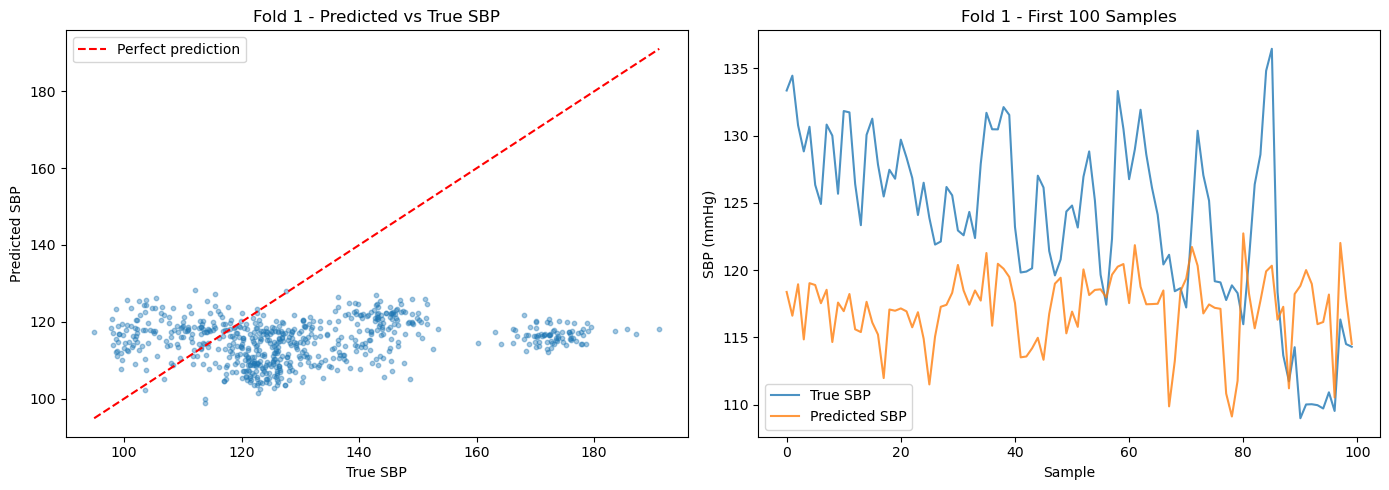

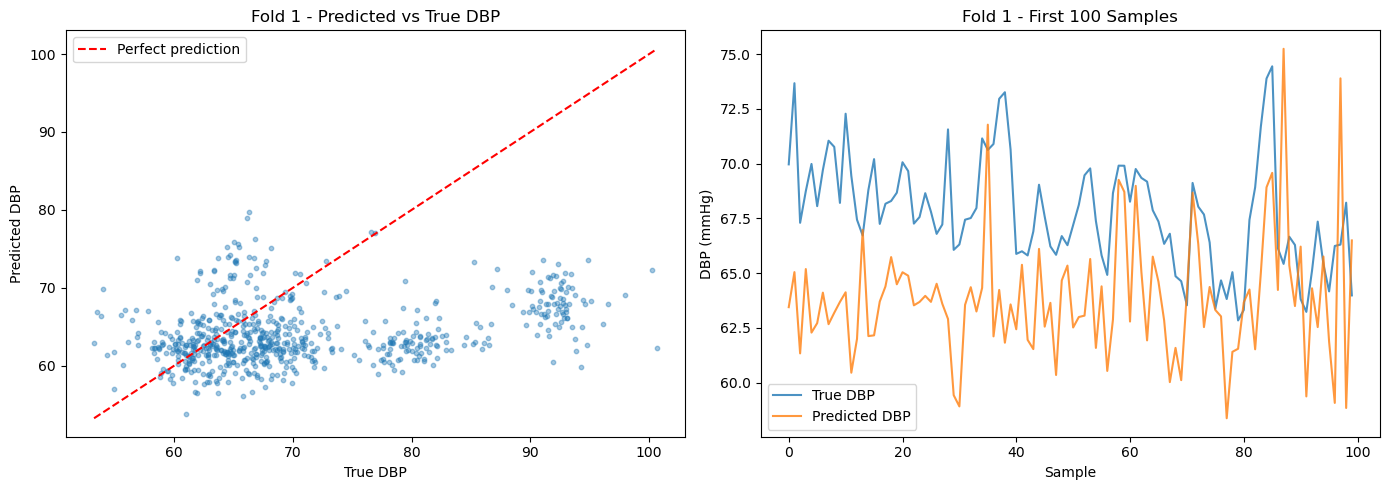

Generalization Error SBP = 19.9547, Generalization Error DBP = 8.8176
Training on Fold 2/5
Epoch 1, Training Loss: 287.4939
Epoch 2, Training Loss: 205.8272
Epoch 3, Training Loss: 188.0671
Epoch 4, Training Loss: 173.0988
Epoch 5, Training Loss: 172.0013
Epoch 6, Training Loss: 165.7973
Epoch 7, Training Loss: 160.0322
Epoch 8, Training Loss: 156.9942
Epoch 9, Training Loss: 152.8492
Epoch 10, Training Loss: 150.7375


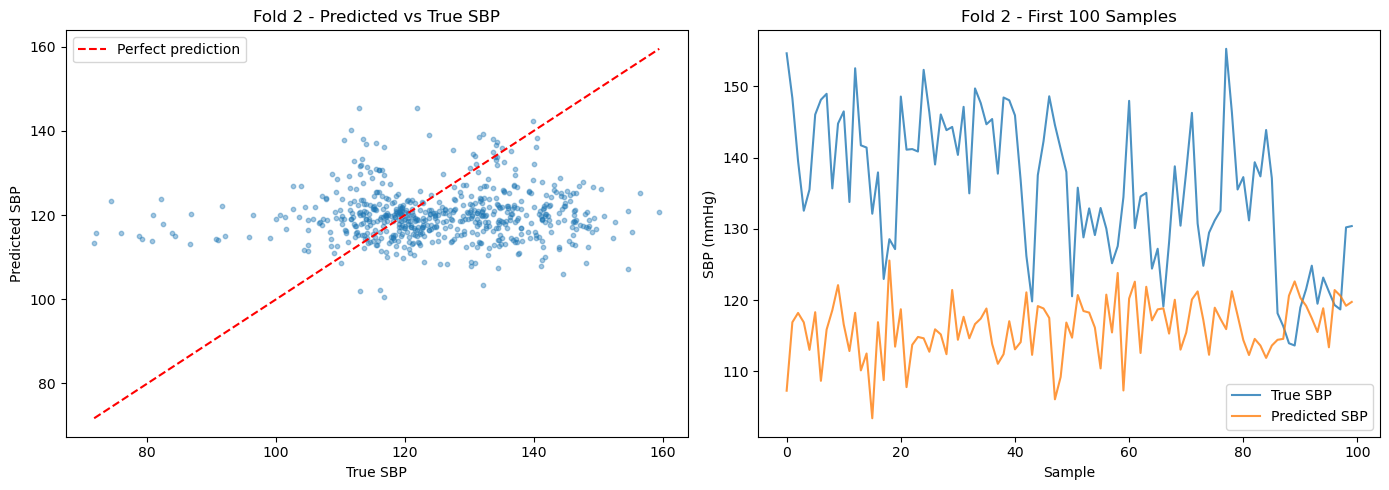

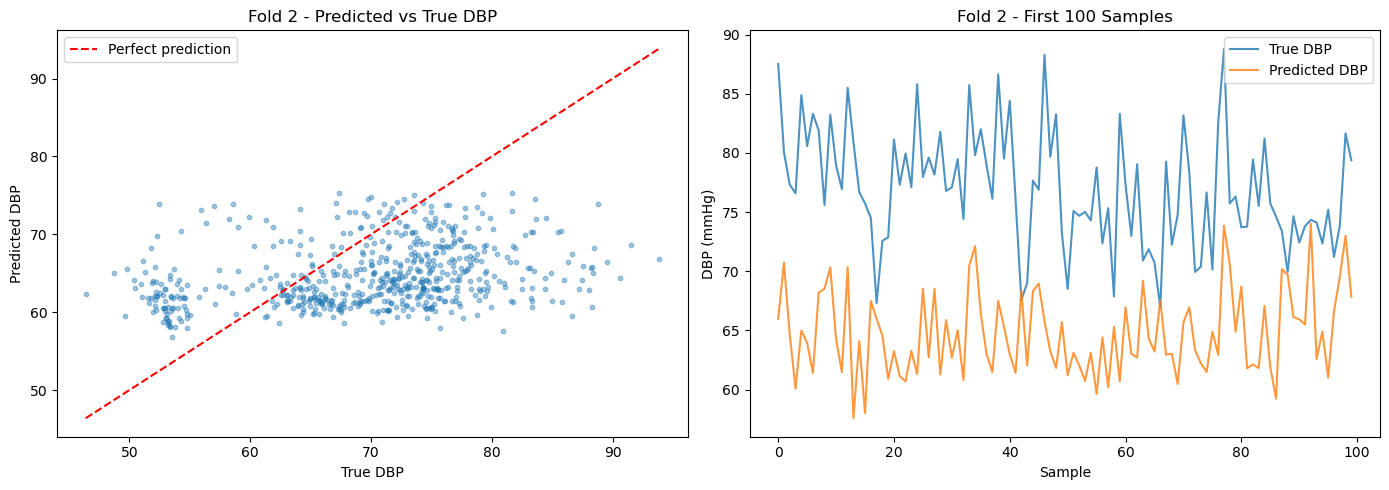

Generalization Error SBP = 12.3395, Generalization Error DBP = 8.4849
Training on Fold 3/5
Epoch 1, Training Loss: 348.6012
Epoch 2, Training Loss: 251.5229
Epoch 3, Training Loss: 211.5768
Epoch 4, Training Loss: 197.8877
Epoch 5, Training Loss: 196.1656
Epoch 6, Training Loss: 194.3344
Epoch 7, Training Loss: 181.5535
Epoch 8, Training Loss: 184.6514
Epoch 9, Training Loss: 178.8527
Epoch 10, Training Loss: 183.0092


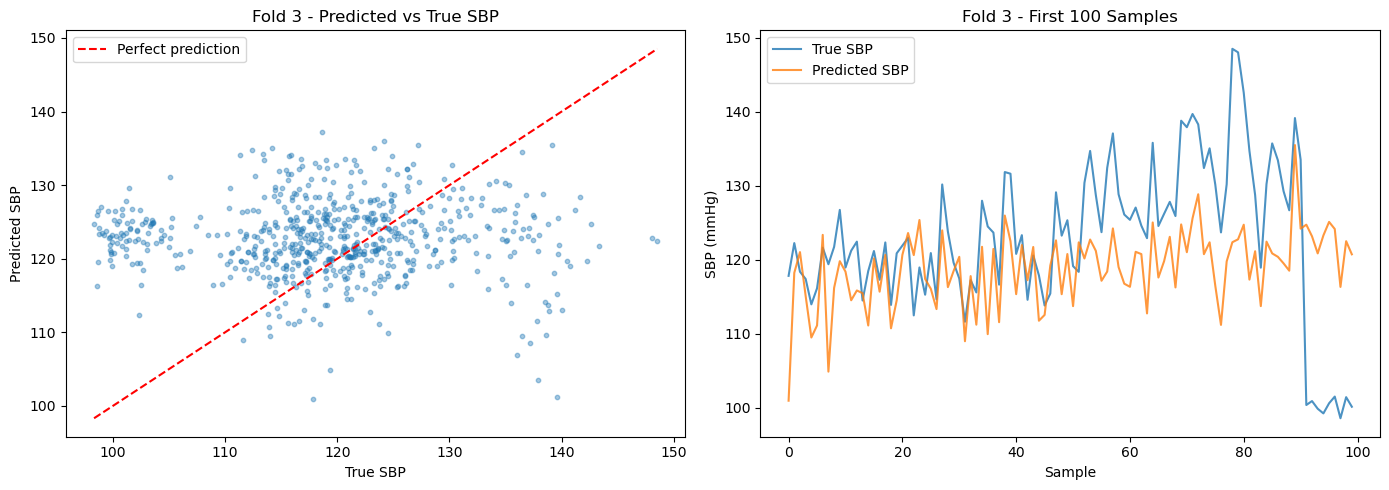

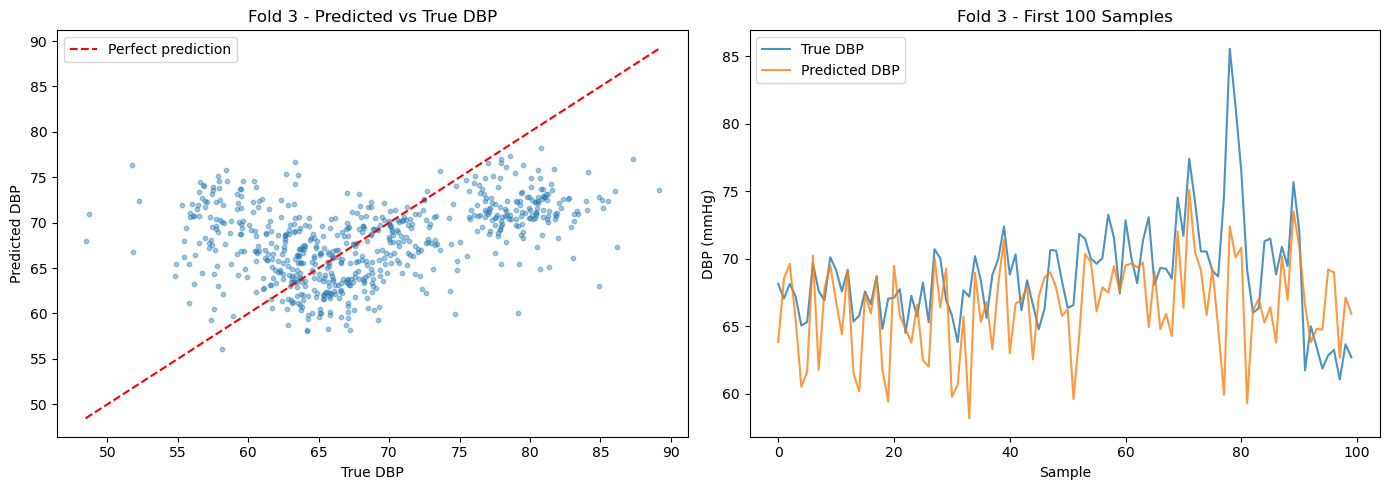

Generalization Error SBP = 9.0551, Generalization Error DBP = 5.9478
Training on Fold 4/5
Epoch 1, Training Loss: 225.4351
Epoch 2, Training Loss: 187.5025
Epoch 3, Training Loss: 175.9817
Epoch 4, Training Loss: 172.6133
Epoch 5, Training Loss: 165.4507
Epoch 6, Training Loss: 157.7954
Epoch 7, Training Loss: 154.0293
Epoch 8, Training Loss: 155.5644
Epoch 9, Training Loss: 154.6395
Epoch 10, Training Loss: 148.5361


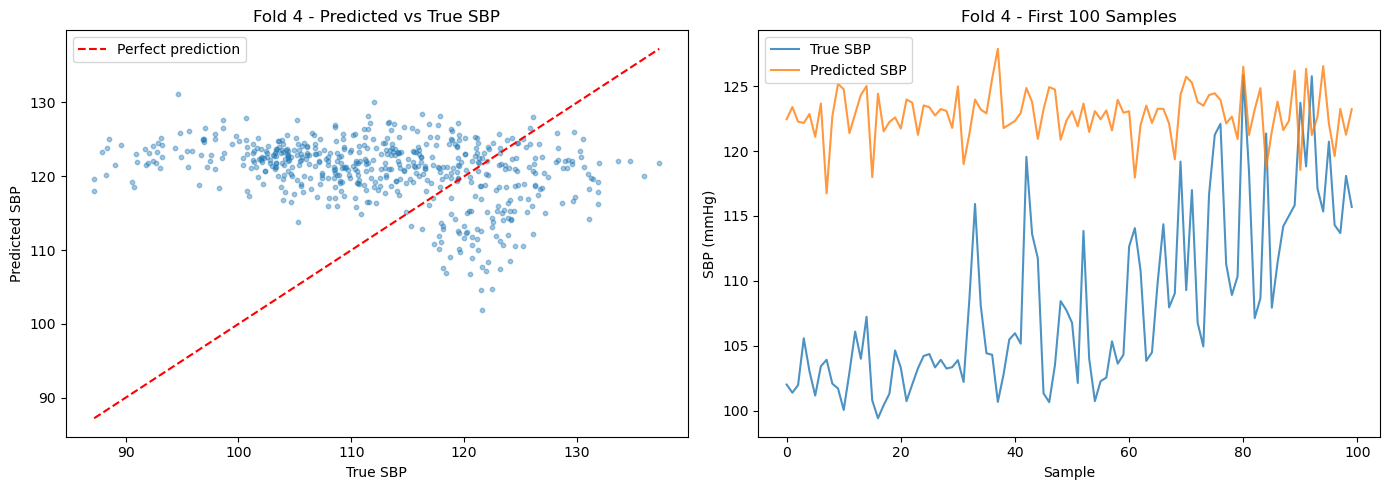

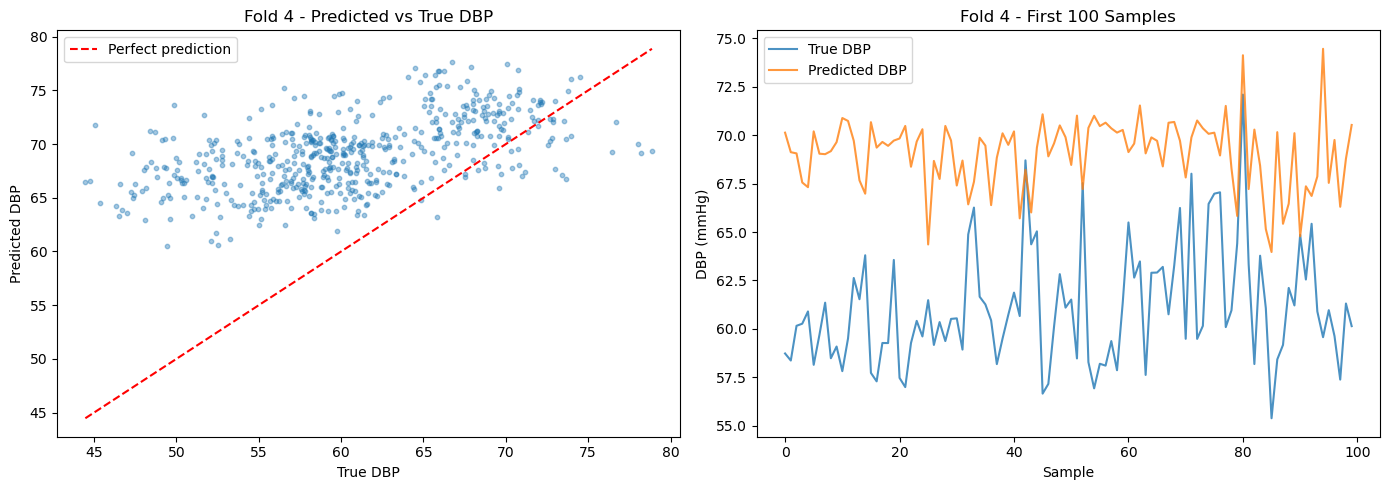

Generalization Error SBP = 12.1366, Generalization Error DBP = 8.9514
Training on Fold 5/5
Epoch 1, Training Loss: 239.6396
Epoch 2, Training Loss: 192.0056
Epoch 3, Training Loss: 185.2070
Epoch 4, Training Loss: 177.9065
Epoch 5, Training Loss: 174.1813
Epoch 6, Training Loss: 168.8122
Epoch 7, Training Loss: 165.8285
Epoch 8, Training Loss: 167.5268
Epoch 9, Training Loss: 161.4739
Epoch 10, Training Loss: 158.3421


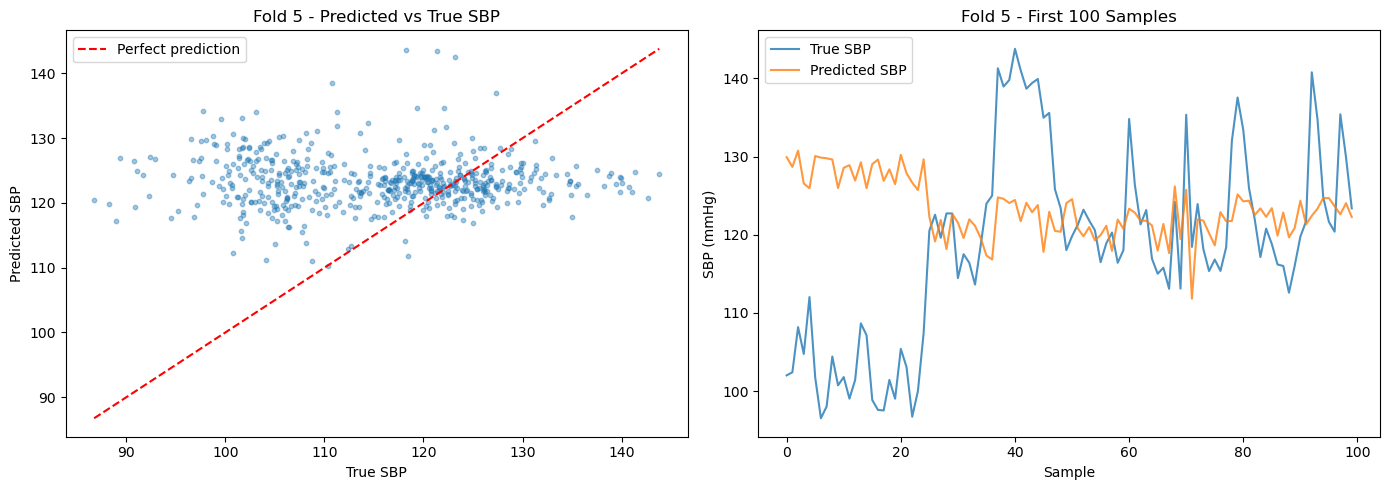

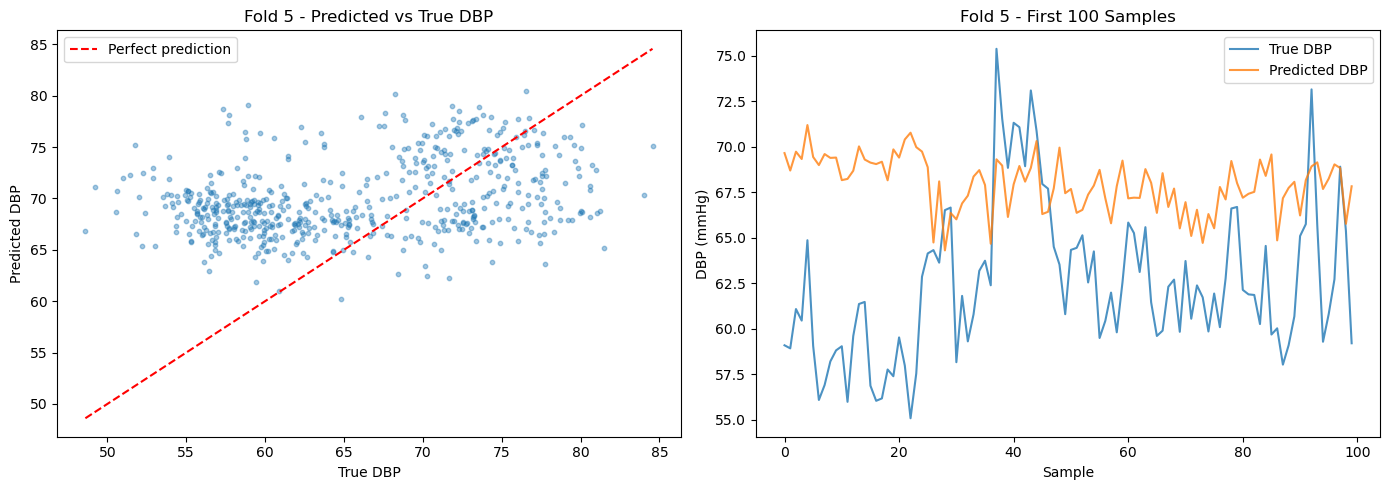

Generalization Error SBP = 10.9966, Generalization Error DBP = 7.3641
Final CV MAE's: 
SBP: 13.0222 ± 3.7168, 
DBP: 7.8943 ± 1.1302


In [45]:
"""
In this case the approach was to divide SP and DP in 100 intervals, from their respective min and max values.
During training and inference, the ouput layer of the net are divided in two groups, of same size, than the firing rate of this neurons are used to predict the label.
eg.
We use 200 ouput neuron since we have 100 interval/classes. 100 of them refers to the SP and 100.
Each neuron correspond to an interval value, and we use the firing rate of each neuron to do a weighted sum and predict the blood pressure.
[70, 82,...190] 100 values evenly spaced
Final prediction = [70, 82,...190] * [firing rate of each neuron]'/[sum of the firining rates]
"""


#most_important_features = ["TdiaToEnd","T_peak_e","TdiaRise","TSystoDiaRise", "T_peak_a","T_peak_e_norm","Td"]
most_important_features = ["TdiaToEnd","T_a_norm","S4_norm","TSystoDiaRise", "ppg_histogram_down_2","S4","ppg4_histogram_down_5","T_e_norm","ppg3_histogram_down_8","usdc_2"]

batch_size = 32 # CHANGED from 1 to 32
num_epochs = 10 # CHANGED from 2 to 10
num_inputs = 10
num_hidden  = 30
num_hidden2 = 200
num_outputs = 200
num_steps   = 40
beta_val    = 0.95
num_folds = 5

'''
net = Net(
    num_inputs=num_inputs,
    num_hidden=num_hidden,
    num_hidden2=num_hidden2,
    num_outputs=num_outputs,
    beta_val=beta_val,
    num_steps=num_steps
).to(device)
'''

preferred_values_sbp = torch.linspace(70, 190, 100).to(device)
preferred_values_dbp = torch.linspace(45, 101, 100).to(device)

cv_mae_sbp = 0.0    # Cross Validation Mean Absolute Error for SBP
cv_mae_dbp = 0.0
cv_total_samples = 0
fold_maes_sbp = []  # To collect per-fold MAE
fold_maes_dbp = []


for fold in range(5):
    net = Net(
        num_inputs=num_inputs,
        num_hidden=num_hidden,
        num_hidden2=num_hidden2,
        num_outputs=num_outputs,
        beta_val=beta_val,
        num_steps=num_steps
    ).to(device)

    all_predictions_sbp = []    # For visualization
    all_true_sbp = []
    all_predictions_dbp = []
    all_true_dbp = []

    print(f"Training on Fold {fold + 1}/{num_folds}")

    test_data = load_data(fold)
    train_data = pd.concat([load_data(i) for i in range(num_folds) if i!= fold])

    X_train, y_train = train_data[most_important_features], train_data.iloc[:, 2:4]
    X_test, y_test = test_data[most_important_features], test_data.iloc[:, 2:4]

    X_min = X_train.min()
    X_max = X_train.max()
    X_train = (X_train - X_min) / (X_max - X_min + 1e-8)
    X_test = (X_test - X_min) / (X_max - X_min + 1e-8)


    X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32)
    X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32)

    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


    loss_fn = nn.MSELoss()
    optimizer = optim.Adam(net.parameters(), lr=5e-4)

    for epoch in range(num_epochs):
        net.train()
        cont = 0
        num_batches = 0
        total_train_loss = 0
        for batch_x, batch_y in train_loader:
            optimizer.zero_grad()
            spk_out = net(batch_x)

            firing_rates = torch.mean(spk_out, dim=0)
            firing_rates_sbp = firing_rates[:, :100]
            firing_rates_dbp = firing_rates[:, 100:]

            topk_sp = torch.topk(firing_rates_sbp, k=10, dim=1, largest=True)[1]
            topk_dp = torch.topk(firing_rates_dbp, k=10, dim=1, largest=True)[1]

            top_firing_rates_sp = torch.gather(firing_rates_sbp, 1, topk_sp)
            top_preferred_values_sp = preferred_values_sbp[topk_sp]
            predicted_sbp = torch.sum(top_firing_rates_sp * top_preferred_values_sp, dim=1) / torch.sum(top_firing_rates_sp, dim=1)

            top_firing_rates_dp = torch.gather(firing_rates_dbp, 1, topk_dp)
            top_preferred_values_dp = preferred_values_dbp[topk_dp]
            predicted_dbp = torch.sum(top_firing_rates_dp * top_preferred_values_dp, dim=1) / torch.sum(top_firing_rates_dp, dim=1)

            loss = loss_fn(predicted_sbp, batch_y[:, 0]) + loss_fn(predicted_dbp, batch_y[:, 1])
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item()
            num_batches += 1

        print(f"Epoch {epoch + 1}, Training Loss: {total_train_loss / num_batches:.4f}")
    
    net.eval()
    total_samples = 0
    total_mae_sbp = 0    # Generalization Error for SBP calculated per fold
    total_mae_dbp = 0
    
    with torch.no_grad():
        for test_x, test_y in test_loader:
            batch_size = test_x.shape[0]
            outputs = net(test_x)

            firing_rates = torch.mean(outputs, dim=0)
            firing_rates_sbp = firing_rates[:, :100]
            firing_rates_dbp = firing_rates[:, 100:]

            
            predicted_sbp = torch.sum(firing_rates_sbp * preferred_values_sbp, dim=1) / torch.sum(firing_rates_sbp, dim=1)
            predicted_dbp = torch.sum(firing_rates_dbp * preferred_values_dbp, dim=1) / torch.sum(firing_rates_dbp, dim=1)
            all_predictions_sbp.extend(predicted_sbp.cpu().numpy())
            all_true_sbp.extend(test_y[:, 0].cpu().numpy())
            
            all_predictions_dbp.extend(predicted_dbp.cpu().numpy())
            all_true_dbp.extend(test_y[:, 1].cpu().numpy())
            
            '''
            topk_sp = torch.topk(firing_rates_sbp, k=10, dim=1, largest=True)[1]
            topk_dp = torch.topk(firing_rates_dbp, k=10, dim=1, largest=True)[1]

            top_firing_rates_sp = torch.gather(firing_rates_sbp, 1, topk_sp)
            top_preferred_values_sp = preferred_values_sbp[topk_sp]
            predicted_sbp = torch.sum(top_firing_rates_sp * top_preferred_values_sp, dim=1) / torch.sum(top_firing_rates_sp, dim=1)

            top_firing_rates_dp = torch.gather(firing_rates_dbp, 1, topk_dp)
            top_preferred_values_dp = preferred_values_dbp[topk_dp]
            predicted_dbp = torch.sum(top_firing_rates_dp * top_preferred_values_dp, dim=1) / torch.sum(top_firing_rates_dp, dim=1)
            '''

            mae_sbp = torch.abs(predicted_sbp - test_y[:, 0]).sum().item()
            mae_dbp = torch.abs(predicted_dbp - test_y[:, 1]).sum().item()

            total_mae_sbp += mae_sbp
            total_mae_dbp += mae_dbp
            total_samples += batch_size
    
    plot_predictions(np.array(all_true_sbp), np.array(all_predictions_sbp), "SBP", fold)
    plot_predictions(np.array(all_true_dbp), np.array(all_predictions_dbp), "DBP", fold)
            

    fold_mae_sbp = total_mae_sbp / total_samples
    fold_mae_dbp = total_mae_dbp / total_samples   

    fold_maes_sbp.append(fold_mae_sbp)
    fold_maes_dbp.append(fold_mae_dbp)

    cv_mae_sbp += total_mae_sbp
    cv_mae_dbp += total_mae_dbp
    cv_total_samples += total_samples

    print(f"Generalization Error SBP = {total_mae_sbp / total_samples:.4f}, Generalization Error DBP = {total_mae_dbp / total_samples:.4f}")

print(f"Final CV MAE's: \nSBP: {cv_mae_sbp / cv_total_samples:.4f} ± {np.std(fold_maes_sbp):.4f}, \nDBP: {cv_mae_dbp / cv_total_samples:.4f} ± {np.std(fold_maes_dbp):.4f}")